In [1]:
from scripts.read_field import read_dir
from scripts.mm.experiment import Experiment
import os 
import numpy as np 
from typing import Literal
from scripts.scientific import apply
import matplotlib.pyplot as plt
apply()

In [47]:
path = os.path.join("./02-attraction/skyrmion_system")
runs = sorted([os.path.join(path, d) for d in os.listdir(path) if d.startswith("drive-")])[:]
data = [read_dir(run) for run in runs]
experiments = [Experiment.load(run) for run in runs]

In [48]:
def trajectory(data, experiment: Experiment, method: Literal['center', 'charge'] = 'center'):
    xs = np.array([])
    ys = np.array([])
    W = experiment.width / experiment.dx
    H = experiment.height / experiment.dx
    X, Y = np.meshgrid(np.arange(-W, W) * experiment.dx, -np.arange(-H, H) * experiment.dx)
    for i in range(len(data)):
        if method == 'center':
            weight = (1- data[i,:,:,2]) ** 2
        if method == 'charge':
            weight = np.sum(data[i] * np.linalg.cross(np.gradient(data[i], axis=0), np.gradient(data[i], axis=1)), axis=2)
        norm = np.sum(weight)

        x = np.sum(weight * X) / norm
        y = np.sum(weight * Y) / norm
        xs = np.append(xs, x)
        ys = np.append(ys, y)

    xs = xs - experiment.vortex_to[0]
    ys = ys - experiment.vortex_to[1]
    return xs, ys

[np.float64(2.9645655357207596), np.float64(2.8459098920581685)] [np.float64(0.01249999999999974), np.float64(-0.07383771719647995)]


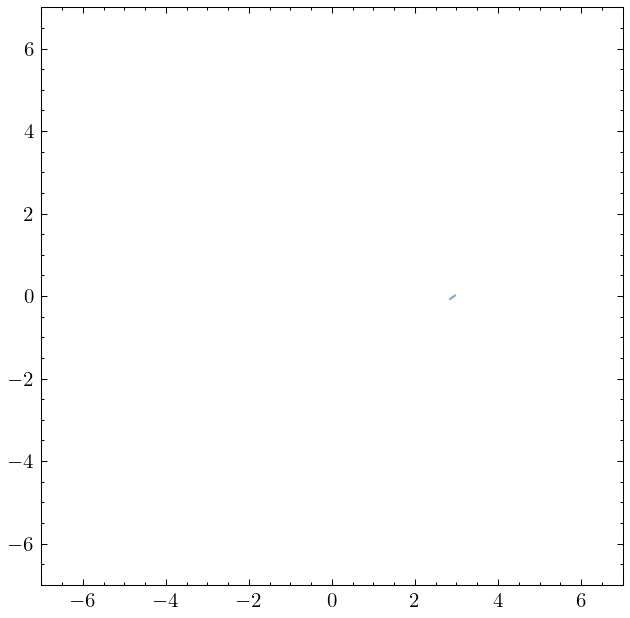

In [49]:
ts = [trajectory(d, e, method='charge') for d, e in zip(data, experiments)]
xs, ys = [], []
curr = [np.float64(0), np.float64(0)]

for t in ts:
    xs = [*xs, *t[0]]
    ys = [*ys, *t[1]]
    curr[0] = xs[-1]
    curr[1] = ys[-1]

plt.subplots(figsize=(5,5))
plt.plot(xs, ys)
plt.xlim([-7,7])
plt.ylim([-7,7])

print(xs, ys)

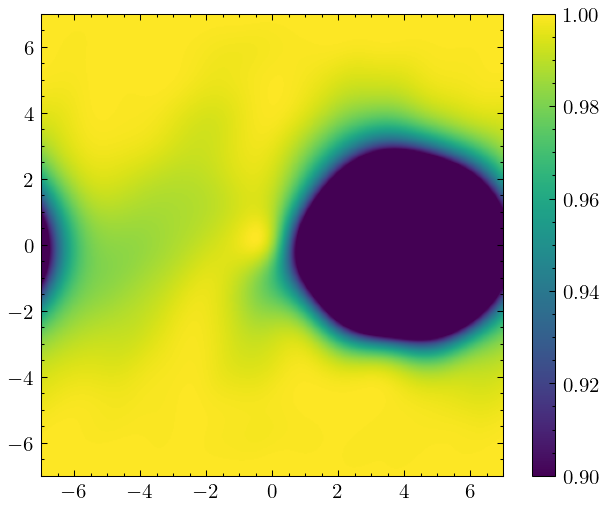

In [56]:
plt.imshow(data[-1][1,:,:,2], extent=([-7, 7, -7, 7]), vmin=0.9, vmax=1)
plt.colorbar()
# plt.plot(*ts[1])